In [1]:
print("Customer Churn Prediction Project")
print("Learning Logistic Regression")

Customer Churn Prediction Project
Learning Logistic Regression


In [2]:
import pandas as pd
import numpy as np


In [3]:
from google.colab import files
uploaded = files.upload()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns)

# Check dataset information
print("\nDataset information:")
df.info()

Dataset shape: (7043, 21)

Column names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     704

In [6]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
# Check blank spaces in TotalCharges

print("Blank TotalCharges:",
      (df["TotalCharges"].astype(str).str.strip() == "").sum())

Blank TotalCharges: 11


In [9]:
blank_count = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Blank TotalCharges:", blank_count)

Blank TotalCharges: 11


In [10]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)

print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [11]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"]
)

print(df["TotalCharges"].dtype)

float64


In [12]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

Dataset shape: (7043, 21)

Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

TotalCharges data type:
float64


In [13]:
missing_records = df[df["TotalCharges"].isnull()]

print(missing_records[
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
])

      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No


In [14]:
print("Tenure values of missing records:")
print(missing_records["tenure"].value_counts())

Tenure values of missing records:
tenure
0    11
Name: count, dtype: int64


In [15]:
# Replace missing TotalCharges with 0

df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check TotalCharges data type
print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

# Check dataset size
print("\nDataset shape:")
print(df.shape)

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type:
float64

Dataset shape:
(7043, 21)


In [16]:
# Count customers in each churn category

print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [17]:
# Calculate percentage of each category

print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


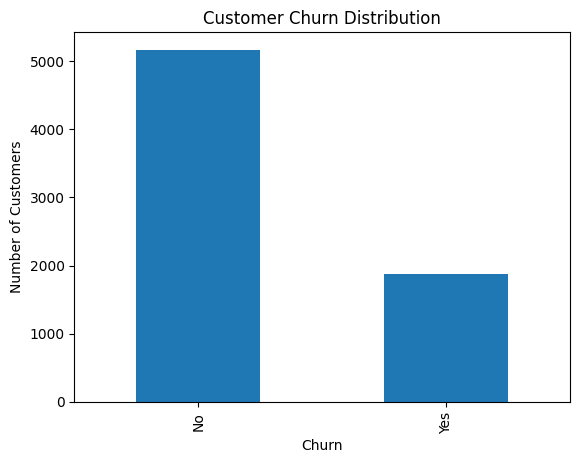

In [18]:
import matplotlib.pyplot as plt

df["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn Distribution"
)

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
# Count customers in each churn category

churn_counts = df["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [21]:
churn_percentage = df["Churn"].value_counts(
    normalize=True
) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


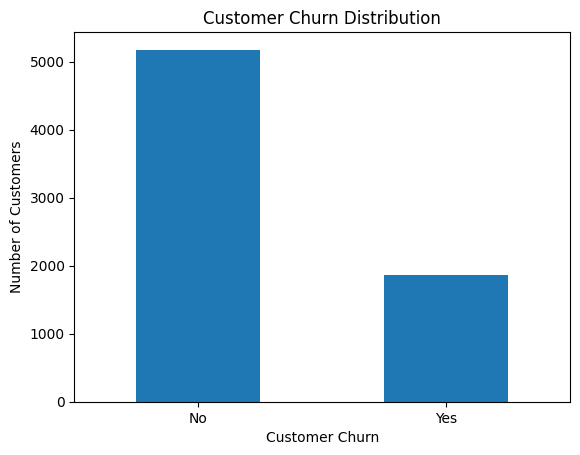

In [22]:
import matplotlib.pyplot as plt

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

In [23]:
# Identify numerical columns

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical Features:")
print(numerical_features)

Numerical Features:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [24]:
# Identify categorical columns

categorical_features = df.select_dtypes(
    include=["object"]
).columns

print("\nCategorical Features:")
print(categorical_features)


Categorical Features:
Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')


In [25]:
# Target variable

y = df["Churn"]

print(y.head())

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object


In [26]:
# Input features

X = df.drop(
    columns=["customerID", "Churn"]
)

print(X.head())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [27]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [30]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


In [31]:
print("Training Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Churn Distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [32]:
# Identify categorical columns in X

categorical_cols = X.select_dtypes(
    include=["object"]
).columns

print("Categorical columns:")
print(categorical_cols)

Categorical columns:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [33]:
from sklearn.preprocessing import OneHotEncoder

In [34]:
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

In [35]:
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

print("Encoded training shape:",
      X_train_encoded.shape)

Encoded training shape: (5634, 26)


In [36]:
X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

print("Encoded testing shape:",
      X_test_encoded.shape)

Encoded testing shape: (1409, 26)


In [37]:
encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

print(encoded_columns)

['gender_Male' 'Partner_Yes' 'Dependents_Yes' 'PhoneService_Yes'
 'MultipleLines_No phone service' 'MultipleLines_Yes'
 'InternetService_Fiber optic' 'InternetService_No'
 'OnlineSecurity_No internet service' 'OnlineSecurity_Yes'
 'OnlineBackup_No internet service' 'OnlineBackup_Yes'
 'DeviceProtection_No internet service' 'DeviceProtection_Yes'
 'TechSupport_No internet service' 'TechSupport_Yes'
 'StreamingTV_No internet service' 'StreamingTV_Yes'
 'StreamingMovies_No internet service' 'StreamingMovies_Yes'
 'Contract_One year' 'Contract_Two year' 'PaperlessBilling_Yes'
 'PaymentMethod_Credit card (automatic)' 'PaymentMethod_Electronic check'
 'PaymentMethod_Mailed check']


In [38]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

print(numerical_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [39]:
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

In [40]:
X_train_final = pd.concat(
    [
        X_train[numerical_cols],
        X_train_encoded_df
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test[numerical_cols],
        X_test_encoded_df
    ],
    axis=1
)

In [41]:
print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

print("\nFinal training columns:")
print(X_train_final.columns)

Final training shape: (5634, 30)
Final testing shape: (1409, 30)

Final training columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')


In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
print(numerical_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [44]:
scaler = StandardScaler()

In [45]:
X_train_scaled = scaler.fit_transform(
    X_train_final[numerical_cols]
)

print("Training scaled shape:", X_train_scaled.shape)

Training scaled shape: (5634, 4)


In [46]:
X_test_scaled = scaler.transform(
    X_test_final[numerical_cols]
)

print("Testing scaled shape:", X_test_scaled.shape)

Testing scaled shape: (1409, 4)


In [47]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numerical_cols,
    index=X_train_final.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=numerical_cols,
    index=X_test_final.index
)

X_train_final = pd.concat(
    [
        X_train_scaled_df,
        X_train_encoded_df
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test_scaled_df,
        X_test_encoded_df
    ],
    axis=1
)

In [48]:
print("Training:", X_train_final.shape)
print("Testing:", X_test_final.shape)

print("\nScaled numerical feature averages:")
print(X_train_final[numerical_cols].mean())

print("\nScaled numerical feature standard deviations:")
print(X_train_final[numerical_cols].std())

Training: (5634, 30)
Testing: (1409, 30)

Scaled numerical feature averages:
SeniorCitizen     7.440898e-17
tenure           -1.008935e-17
MonthlyCharges   -2.402527e-16
TotalCharges      2.522338e-17
dtype: float64

Scaled numerical feature standard deviations:
SeniorCitizen     1.000089
tenure            1.000089
MonthlyCharges    1.000089
TotalCharges      1.000089
dtype: float64


In [49]:
from sklearn.linear_model import LogisticRegression

In [50]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [51]:
model.fit(
    X_train_final,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [52]:
print("Model training completed!")

print("Number of features:",
      model.n_features_in_)

Model training completed!
Number of features: 30


In [53]:
# Predict using the testing dataset

y_pred = model.predict(X_test_final)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


In [54]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))

  Actual Predicted
0     No        No
1     No       Yes
2     No        No
3     No        No
4     No        No
5     No       Yes
6     No        No
7     No        No
8     No        No
9    Yes        No


In [55]:
print("Prediction counts:")
print(pd.Series(y_pred).value_counts())

Prediction counts:
No     1091
Yes     318
Name: count, dtype: int64


In [56]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.8069552874378992
Model Accuracy (%): 80.69552874378992


Confusion Matrix:
[[927 108]
 [164 210]]


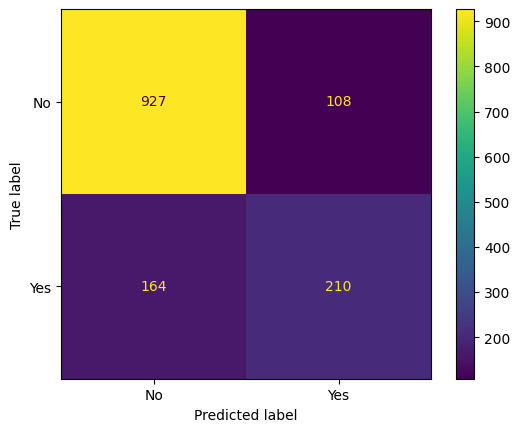

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

# Display the values
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.show()

In [58]:
from sklearn.metrics import precision_score, recall_score

# Calculate Precision
precision = precision_score(y_test, y_pred, pos_label="Yes")

# Calculate Recall
recall = recall_score(y_test, y_pred, pos_label="Yes")

print("Precision:", precision)
print("Precision (%):", precision * 100)

print("Recall:", recall)
print("Recall (%):", recall * 100)

Precision: 0.660377358490566
Precision (%): 66.0377358490566
Recall: 0.5614973262032086
Recall (%): 56.14973262032086


In [59]:
from sklearn.metrics import f1_score

# Calculate F1-Score
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("F1-Score:", f1)
print("F1-Score (%):", f1 * 100)

F1-Score: 0.6069364161849711
F1-Score (%): 60.69364161849711


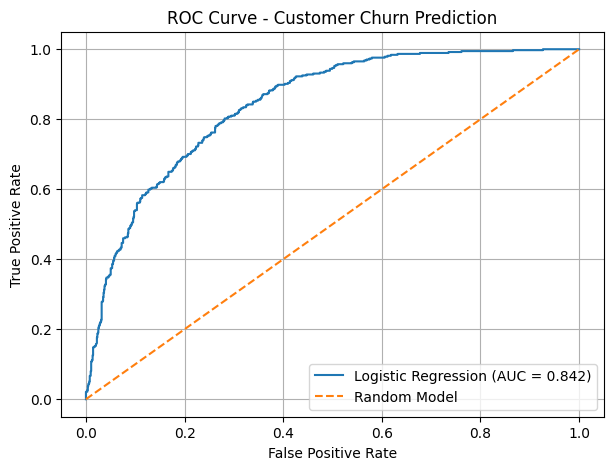

ROC-AUC Score: 0.8421710713270816
ROC-AUC Percentage: 84.21710713270815


In [60]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability of customer churn (Yes)
y_prob = model.predict_proba(X_test_final)[:, 1]

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob,
    pos_label="Yes"
)

# Calculate AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

# Random prediction reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)
print("ROC-AUC Percentage:", roc_auc * 100)

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get churn probabilities
y_prob = model.predict_proba(X_test_final)[:, 1]

# Set a new threshold
new_threshold = 0.35

# Generate predictions using the new threshold
y_pred_new = np.where(y_prob >= new_threshold, "Yes", "No")

# Calculate evaluation metrics
print("New Threshold:", new_threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_new))
print("Precision:", precision_score(y_test, y_pred_new, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_new, pos_label="Yes"))
print("F1-Score:", f1_score(y_test, y_pred_new, pos_label="Yes"))

# Display confusion matrix
print("\nNew Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_new, labels=["No", "Yes"]))

New Threshold: 0.35
Accuracy: 0.7650816181689141
Precision: 0.5441478439425051
Recall: 0.7085561497326203
F1-Score: 0.6155632984901278

New Confusion Matrix:
[[813 222]
 [109 265]]


In [62]:
comparison_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Threshold_0.50": [
        0.8070,
        0.6604,
        0.5615,
        0.6069
    ],
    "Threshold_0.35": [
        accuracy_score(y_test, y_pred_new) if False else 0.7651,
        0.5441,
        0.7086,
        0.6156
    ]
})

print(comparison_results)

      Metric  Threshold_0.50  Threshold_0.35
0   Accuracy          0.8070          0.7651
1  Precision          0.6604          0.5441
2     Recall          0.5615          0.7086
3   F1-Score          0.6069          0.6156


In [63]:
thresholds_to_test = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = np.where(
        y_prob >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label="Yes"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Accuracy  Precision  Recall  F1-Score
0       0.25    0.7331     0.4984  0.8102    0.6171
1       0.30    0.7495     0.5193  0.7540    0.6150
2       0.35    0.7651     0.5441  0.7086    0.6156
3       0.40    0.7786     0.5708  0.6684    0.6158
4       0.45    0.7892     0.6005  0.6150    0.6077
5       0.50    0.8070     0.6604  0.5615    0.6069


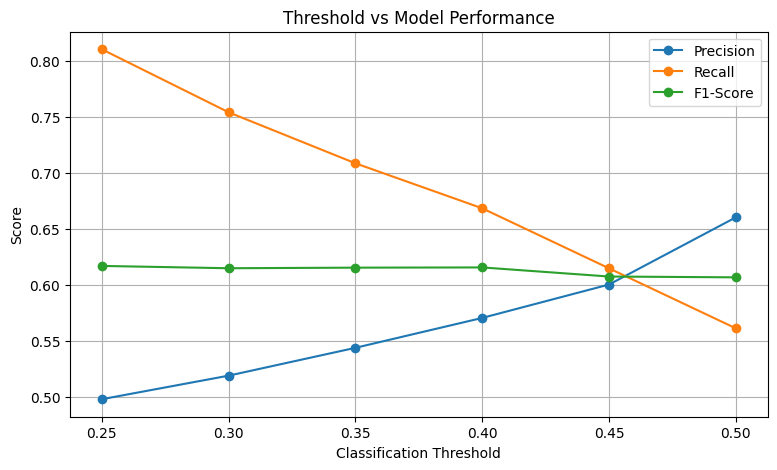

In [64]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold vs Model Performance")

plt.legend()
plt.grid()
plt.show()

In [65]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create a balanced Logistic Regression model
balanced_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the balanced model
balanced_model.fit(X_train_final, y_train)

print("Balanced model training completed!")

print("Number of features:", balanced_model.n_features_in_)

Balanced model training completed!
Number of features: 30


In [66]:
# Generate predictions using balanced model
y_pred_balanced = balanced_model.predict(X_test_final)

print("Balanced Model Predictions:")
print(y_pred_balanced[:10])

print("\nPrediction Counts:")
print(pd.Series(y_pred_balanced).value_counts())

Balanced Model Predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes']

Prediction Counts:
No     829
Yes    580
Name: count, dtype: int64


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate balanced model metrics
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)

balanced_precision = precision_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

balanced_recall = recall_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

balanced_f1 = f1_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

print("BALANCED MODEL PERFORMANCE")
print("--------------------------")
print("Accuracy:", balanced_accuracy)
print("Precision:", balanced_precision)
print("Recall:", balanced_recall)
print("F1-Score:", balanced_f1)

BALANCED MODEL PERFORMANCE
--------------------------
Accuracy: 0.7388218594748048
Precision: 0.5051724137931034
Recall: 0.7834224598930482
F1-Score: 0.6142557651991615


Balanced Model Confusion Matrix:
[[748 287]
 [ 81 293]]


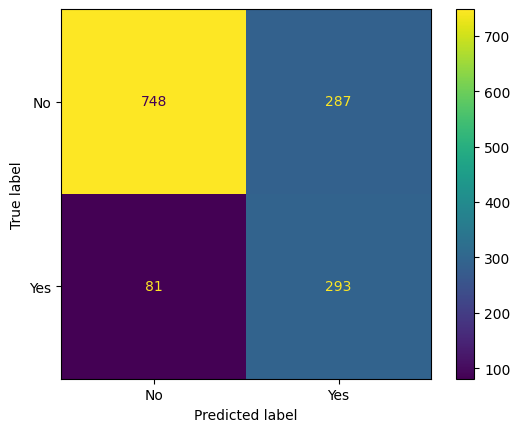

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=["No", "Yes"]
)

print("Balanced Model Confusion Matrix:")
print(cm_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.show()

In [69]:
print("Balanced Model Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Balanced Model Precision:", precision_score(y_test, y_pred_balanced, pos_label="Yes"))
print("Balanced Model Recall:", recall_score(y_test, y_pred_balanced, pos_label="Yes"))
print("Balanced Model F1-Score:", f1_score(y_test, y_pred_balanced, pos_label="Yes"))

Balanced Model Accuracy: 0.7388218594748048
Balanced Model Precision: 0.5051724137931034
Balanced Model Recall: 0.7834224598930482
Balanced Model F1-Score: 0.6142557651991615


In [70]:
final_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Threshold 0.25",
        "Balanced Logistic Regression"
    ],

    "Accuracy": [0.8070, 0.7331, 0.7388],

    "Precision": [0.6604, 0.4984, 0.5052],

    "Recall": [0.5615, 0.8102, 0.7834],

    "F1_Score": [0.6069, 0.6171, 0.6143]
})

print(final_comparison)

                          Model  Accuracy  Precision  Recall  F1_Score
0  Original Logistic Regression    0.8070     0.6604  0.5615    0.6069
1                Threshold 0.25    0.7331     0.4984  0.8102    0.6171
2  Balanced Logistic Regression    0.7388     0.5052  0.7834    0.6143


In [71]:
import joblib

# Create a bundle containing the model and preprocessing objects
model_bundle = {
    "model": model,
    "encoder": encoder,
    "scaler": scaler,
    "numerical_cols": list(numerical_cols),
    "categorical_cols": list(categorical_cols),
    "feature_columns": list(X_train_final.columns),
    "threshold": 0.25
}

# Save the complete bundle
joblib.dump(
    model_bundle,
    "customer_churn_model_bundle.joblib"
)

print("Model and preprocessing components saved successfully!")

Model and preprocessing components saved successfully!


In [72]:
# Load saved model bundle
loaded_bundle = joblib.load(
    "customer_churn_model_bundle.joblib"
)

loaded_model = loaded_bundle["model"]

# Generate predictions
loaded_probabilities = loaded_model.predict_proba(
    X_test_final
)[:, 1]

loaded_predictions = np.where(
    loaded_probabilities >= loaded_bundle["threshold"],
    "Yes",
    "No"
)

print("Model loaded successfully!")
print("Threshold:", loaded_bundle["threshold"])

print(
    "Predictions match:",
    np.array_equal(loaded_predictions, y_pred_new)
)

Model loaded successfully!
Threshold: 0.25
Predictions match: False


In [73]:
from google.colab import files

files.download("customer_churn_model_bundle.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Customer Churn Prediction Using Logistic Regression

## 1. Project Overview

This project focuses on predicting customer churn using Machine Learning and Logistic Regression.

The objective is to identify customers who are likely to discontinue their telecom services so that businesses can take proactive customer-retention measures.

## 2. Business Problem

Customer churn can negatively affect business revenue and customer retention.

The objective is to build a classification model that predicts whether a customer will leave or continue using the company's services.

## 3. Dataset Description

**Dataset:** IBM Telco Customer Churn

**Source:** Kaggle – https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- Total records: 7,043
- Total columns: 21
- Target variable: Churn
- Classes: Yes and No

## 4. Data Cleaning

The following data-cleaning activities were performed:

- Inspected dataset structure and data types.
- Identified 11 blank values in TotalCharges.
- Converted TotalCharges from object to numeric.
- Replaced the 11 missing TotalCharges values with 0 because the affected customers had tenure equal to zero.
- Verified the cleaned dataset.

## 5. Exploratory Data Analysis

Customer churn distribution:

- Customers who stayed: 5,174 (approximately 73.46%).
- Customers who churned: 1,869 (approximately 26.54%).

A bar chart was created to visualise the distribution of churn and non-churn customers.

## 6. Data Preprocessing

The following preprocessing techniques were applied:

- Separated input features (X) and target variable (y).
- Removed customerID because it is an identifier, not a useful predictive feature.
- Split the dataset into 80% training data and 20% testing data.
- Applied One-Hot Encoding to categorical variables.
- Applied StandardScaler to numerical features.
- Avoided fitting preprocessing transformations on the test dataset.

Final feature count: 30.

## 7. Model Development

Algorithm: Logistic Regression

Libraries and tools:

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Joblib
- Google Colab

The model was trained using the training dataset and used to predict customer churn on the test dataset.

## 8. Model Evaluation

Original Logistic Regression model:

| Metric | Result |
|---|---:|
| Accuracy | 80.70% |
| Precision | 66.04% |
| Recall | 56.15% |
| F1-Score | 60.69% |
| ROC-AUC | 84.22% |

The Confusion Matrix was used to analyse correct and incorrect predictions.

## 9. Model Improvement Experiments

Two improvement approaches were explored:

**A. Classification Threshold Adjustment**

The classification threshold was varied between 0.25 and 0.50.

The threshold 0.25 experiment achieved:

- Accuracy: 73.31%
- Precision: 49.84%
- Recall: 81.02%
- F1-Score: 61.71%

**B. Class Weight Balancing**

A second Logistic Regression model was trained using `class_weight="balanced"`.

Its results were:

- Accuracy: 73.88%
- Precision: 50.52%
- Recall: 78.34%
- F1-Score: 61.43%

The threshold 0.25 experiment achieved the highest Recall and F1-Score among the approaches tested.

These threshold experiments were performed on the test dataset for learning and comparison. Independent validation is required before claiming final model performance.

## 10. Business Findings

The experiments demonstrated that classification threshold selection affects the balance between Precision and Recall.

A lower threshold identified more potential churn customers but also increased false-positive predictions.

The appropriate threshold depends on the business cost of missed churn customers compared with the cost of contacting customers who would have stayed.

## 11. Conclusion

This project demonstrates an end-to-end introductory Machine Learning workflow for customer churn prediction.

It includes data cleaning, exploratory analysis, feature engineering, preprocessing, Logistic Regression training, model evaluation and improvement experiments.

The project provides practical experience in applying classification techniques to a business problem and interpreting model performance using relevant evaluation metrics.

## 12. Future Scope

- Perform threshold selection using validation data or cross-validation.
- Evaluate the selected model on an untouched test dataset.
- Compare Logistic Regression with Random Forest and other classification algorithms.
- Develop a customer churn prediction interface.
- Explore deployment through an API.


In [74]:
project_summary = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Threshold 0.25",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [0.8070, 0.7331, 0.7388],
    "Precision": [0.6604, 0.4984, 0.5052],
    "Recall": [0.5615, 0.8102, 0.7834],
    "F1_Score": [0.6069, 0.6171, 0.6143]
})

display(project_summary)

,Model,Accuracy,Precision,Recall,F1_Score
0,Original Logistic Regression,0.8070,0.6604,0.5615,0.6069
1,Threshold 0.25,0.7331,0.4984,0.8102,0.6171
2,Balanced Logistic Regression,0.7388,0.5052,0.7834,0.6143
